,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


Dataset dimension :  (45211, 17)
Total number of data :  45211
Total number of columns :  17
Input features :  16
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 n

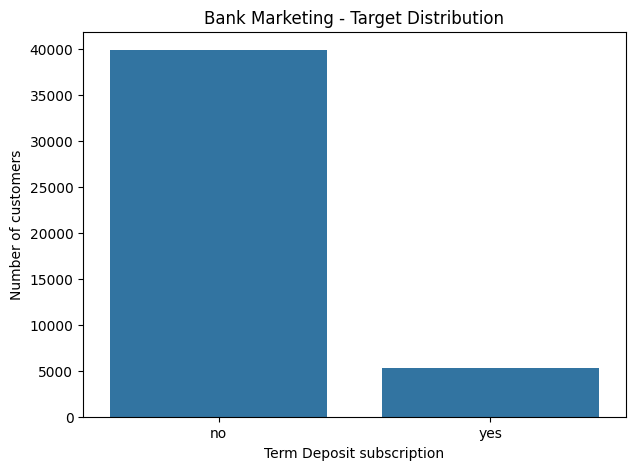

Dataset: Bank Marketing
Source: UCI Machine Learning Repository
Total Instances: 45211
Original Input Features: 16
Target Column: y
Problem Type: Binary Classification
Classes: yes / no


In [1]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

#Loading dataset
df = pd.read_csv("bank-full.csv", sep=";")
display(df.head())

print("Dataset dimension : ", df.shape)
print("Total number of data : ", df.shape[0])
print("Total number of columns : ", df.shape[1])

#Feature and Target
X = df.drop(columns=["y"])
y = df["y"]

print("Input features : ", X.shape[1])
print(df.columns.tolist())
df.info()

#Check missing values
missing_values = df.isnull().sum()
print("Missing values in each columns:")
print(missing_values)

#Duplicate records
print("Duplicate records:", df.duplicated().sum())

#Target
print(df["y"].value_counts())
print("Target percentage:")
print(df["y"].value_counts(normalize=True)*100)

#Visualize
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="y")
plt.title("Bank Marketing - Target Distribution")
plt.xlabel("Term Deposit subscription")
plt.ylabel("Number of customers")
plt.show()

#Dataset info
dataset_info = {
    "Dataset": "Bank Marketing",
    "Source": "UCI Machine Learning Repository",
    "Total Instances": df.shape[0],
    "Original Input Features": 16,
    "Target Column": "y",
    "Problem Type": "Binary Classification",
    "Classes": "yes / no"
}

for key, value in dataset_info.items():
    print(f"{key}: {value}")

In [2]:
#Copy
data = df.copy()

#Data preprocessing - Dropping duration to prevent target leakage
print("Updated dataset shape:", data.shape)
print("Number of input features:", data.shape[1] - 1)

# Independent variables
X = data.drop(columns=["y"])

# Dependent variable
y = data["y"]

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

y = y.map({
    "no": 0,
    "yes": 1
})

print(y.value_counts())

#Test Train split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Updated dataset shape: (45211, 17)
Number of input features: 16
Input features shape: (45211, 16)
Target variable shape: (45211,)
y
0    39922
1     5289
Name: count, dtype: int64
Training feature shape: (36168, 16)
Testing feature shape: (9043, 16)
Training target shape: (36168,)
Testing target shape: (9043,)
Numerical features:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Number of numerical features: 7
Number of categorical features: 9


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Handle numerical features
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Handle categorical features
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [4]:
# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data without fitting again
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("Training data type:", type(X_train_processed))

print("========== DATA PREPARATION SUMMARY ==========")

print("Original dataset:", df.shape)
print("Dataset after removing duration:", data.shape)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

print("Missing values in training target:", y_train.isnull().sum())
print("Missing values in testing target:", y_test.isnull().sum())

print("==============================================")

Processed training shape: (36168, 51)
Processed testing shape: (9043, 51)
Training data type: <class 'numpy.ndarray'>
========== DATA PREPARATION SUMMARY ==========
Original dataset: (45211, 17)
Dataset after removing duration: (45211, 17)
Training samples: 36168
Testing samples: 9043
Numerical features: 7
Categorical features: 9
Processed training data: (36168, 51)
Processed testing data: (9043, 51)
Missing values in training target: 0
Missing values in testing target: 0


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import SVC

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

import pandas as pd
import numpy as np
import time

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": CalibratedClassifierCV(
    estimator=SVC(
        kernel="rbf",
        random_state=42
    ),
    method="sigmoid",
    cv=3,
    ensemble=False
)
}

print("Five classification models defined successfully!")

for name in models:
    print(name)

#Model Pipelines
model_pipelines = {}

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessing", preprocessor),
            ("classifier", model)
        ]
    )

    model_pipelines[name] = pipeline

print("All five model pipelines created!")

Five classification models defined successfully!
Logistic Regression
Decision Tree
KNN
Naive Bayes
Support Vector Machine
All five model pipelines created!


In [6]:
#Training models
training_times = {}

for name, pipeline in model_pipelines.items():

    print("\nTraining:", name)

    start_time = time.time()

    pipeline.fit(X_train, y_train)

    end_time = time.time()

    training_times[name] = end_time - start_time

    print("Training completed!")
    print("Time taken:", round(end_time - start_time, 2), "seconds")

print("\nAll five models trained successfully!")

results = []

for name, pipeline in model_pipelines.items():

    # Predict class labels
    y_pred = pipeline.predict(X_test)

    # Predict probabilities
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(y_test, y_prob)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    results.append({
        "ML Model": name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc,
        "Training Time (sec)": training_times[name]
    })

print("Evaluation completed!")


Training: Logistic Regression
Training completed!
Time taken: 1.49 seconds

Training: Decision Tree
Training completed!
Time taken: 0.88 seconds

Training: KNN
Training completed!
Time taken: 0.19 seconds

Training: Naive Bayes
Training completed!
Time taken: 0.21 seconds

Training: Support Vector Machine
Training completed!
Time taken: 125.81 seconds

All five models trained successfully!
Evaluation completed!


In [7]:
comparison_df = pd.DataFrame(results)

# Display metrics rounded to 4 decimal places
display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "AUC": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "MCC": "{:.4f}",
        "Training Time (sec)": "{:.2f}"
    })
)

,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC,Training Time (sec)
0,Logistic Regression,0.9012,0.9056,0.6445,0.3478,0.4518,0.4261,1.49
1,Decision Tree,0.8746,0.7015,0.4649,0.4754,0.4701,0.3990,0.88
2,KNN,0.8962,0.8277,0.5990,0.3403,0.4340,0.4001,0.19
3,Naive Bayes,0.8548,0.8101,0.4059,0.5198,0.4559,0.3774,0.21
4,Support Vector Machine,0.9056,0.9036,0.6796,0.3648,0.4748,0.4531,125.81


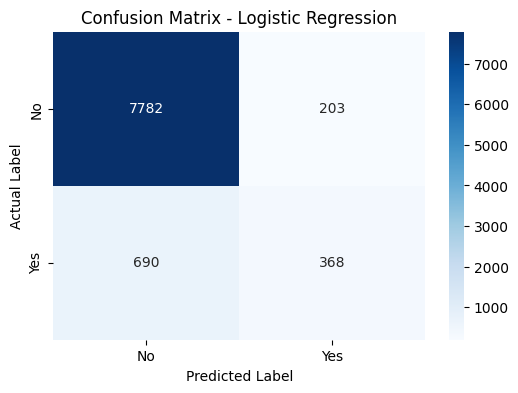

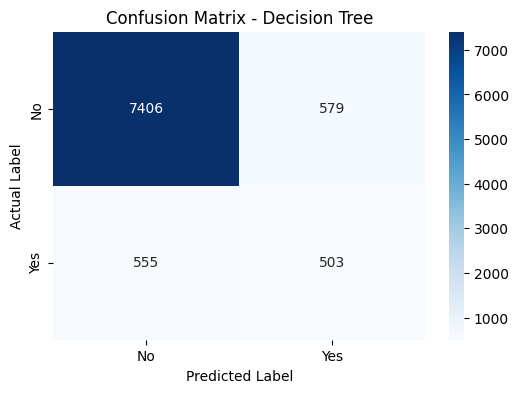

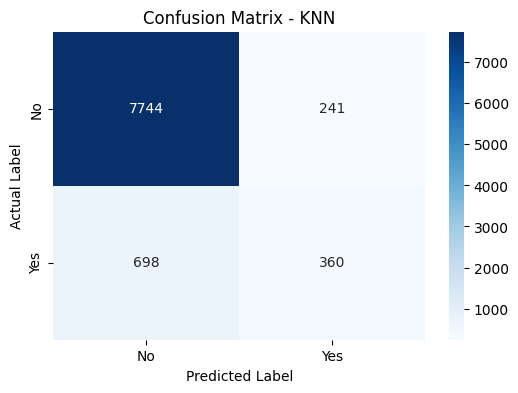

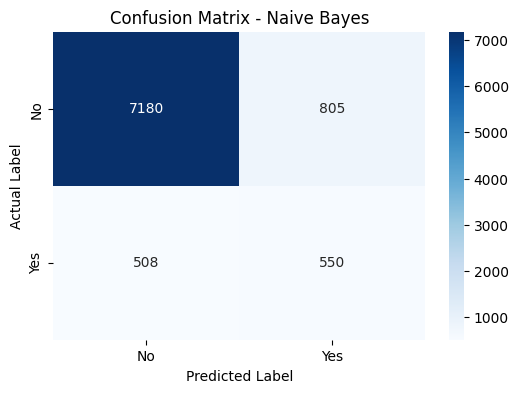

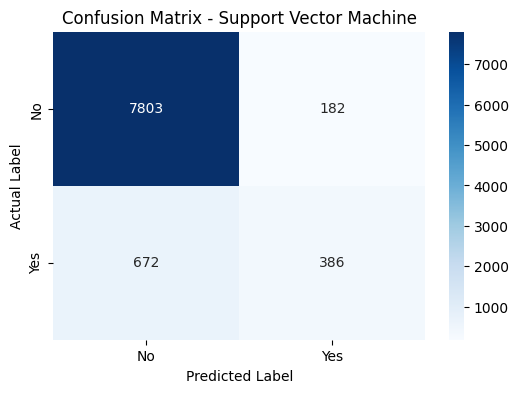

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

for name, pipeline in model_pipelines.items():

    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    plt.show()

In [9]:
for name, pipeline in model_pipelines.items():

    print("\n" + "=" * 60)
    print("MODEL:", name)
    print("=" * 60)

    y_pred = pipeline.predict(X_test)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["No", "Yes"],
            zero_division=0
        )
    )


MODEL: Logistic Regression
              precision    recall  f1-score   support

          No       0.92      0.97      0.95      7985
         Yes       0.64      0.35      0.45      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.66      0.70      9043
weighted avg       0.89      0.90      0.89      9043


MODEL: Decision Tree
              precision    recall  f1-score   support

          No       0.93      0.93      0.93      7985
         Yes       0.46      0.48      0.47      1058

    accuracy                           0.87      9043
   macro avg       0.70      0.70      0.70      9043
weighted avg       0.88      0.87      0.88      9043


MODEL: KNN
              precision    recall  f1-score   support

          No       0.92      0.97      0.94      7985
         Yes       0.60      0.34      0.43      1058

    accuracy                           0.90      9043
   macro avg       0.76      0.66      0.69      9043
weighted avg

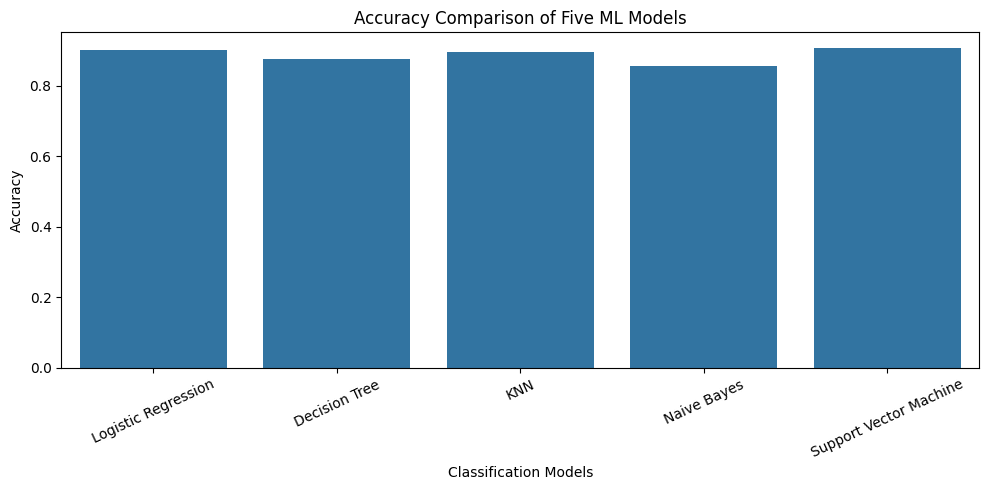

In [10]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison_df,
    x="ML Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Five ML Models")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

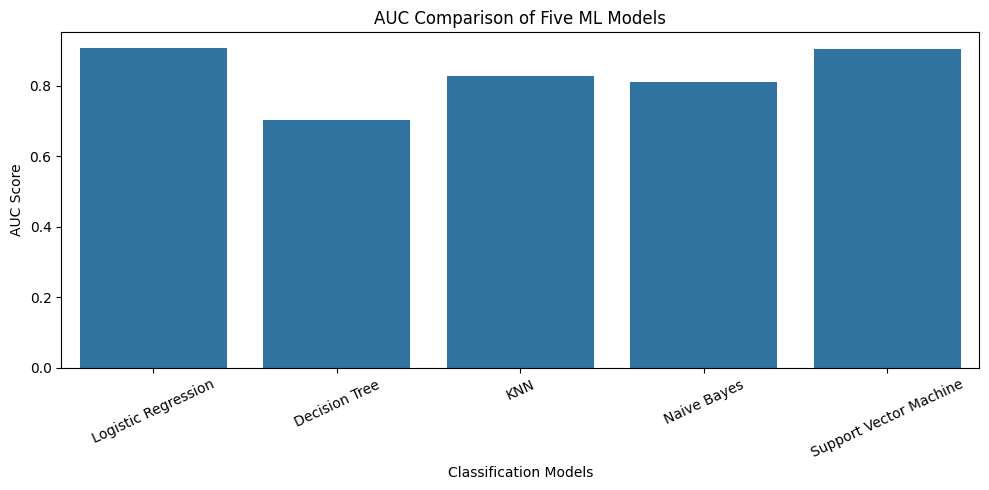

In [11]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison_df,
    x="ML Model",
    y="AUC"
)

plt.title("AUC Comparison of Five ML Models")
plt.xlabel("Classification Models")
plt.ylabel("AUC Score")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [12]:
comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [13]:
import joblib
import os

os.makedirs("model", exist_ok=True)

model_file_names = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

for name, pipeline in model_pipelines.items():

    file_name = model_file_names[name]

    joblib.dump(
        pipeline,
        os.path.join("model", file_name)
    )

    print("Saved:", file_name)

Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: knn.joblib
Saved: naive_bayes.joblib
Saved: svm.joblib


In [14]:
metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

print("BEST MODEL FOR EACH METRIC")
print("=" * 50)

for metric in metrics:

    best_index = comparison_df[metric].idxmax()

    best_model = comparison_df.loc[
        best_index, "ML Model"
    ]

    best_score = comparison_df.loc[
        best_index, metric
    ]

    print(
        f"{metric}: {best_model} ({best_score:.4f})"
    )

# Calculate ranking for each metric
rank_df = comparison_df[["ML Model"]].copy()

for metric in metrics:

    rank_df[metric + " Rank"] = (
        comparison_df[metric]
        .rank(ascending=False, method="average")
    )

# Calculate average rank
rank_columns = [
    metric + " Rank" for metric in metrics
]

rank_df["Average Rank"] = rank_df[
    rank_columns
].mean(axis=1)

# Lower average rank is better
rank_df = rank_df.sort_values(
    "Average Rank"
)

display(rank_df.round(3))

winner = rank_df.iloc[0]["ML Model"]

print("\nOVERALL WINNER:", winner)

print("=" * 65)
print("MODEL PERFORMANCE OBSERVATIONS")
print("=" * 65)

for _, row in comparison_df.iterrows():

    print("\nModel:", row["ML Model"])

    print("Accuracy:", round(row["Accuracy"], 4))
    print("AUC:", round(row["AUC"], 4))
    print("Precision:", round(row["Precision"], 4))
    print("Recall:", round(row["Recall"], 4))
    print("F1 Score:", round(row["F1 Score"], 4))
    print("MCC:", round(row["MCC"], 4))

    if row["Recall"] < row["Precision"]:
        print(
            "Observation: The model has lower recall "
            "than precision, indicating it misses some "
            "actual positive cases."
        )

    elif row["Precision"] < row["Recall"]:
        print(
            "Observation: The model has lower precision "
            "than recall, indicating more false positive "
            "predictions."
        )

    else:
        print(
            "Observation: Precision and recall are "
            "relatively balanced."
        )

    print("-" * 65)

BEST MODEL FOR EACH METRIC
Accuracy: Support Vector Machine (0.9056)
AUC: Logistic Regression (0.9056)
Precision: Support Vector Machine (0.6796)
Recall: Naive Bayes (0.5198)
F1 Score: Support Vector Machine (0.4748)
MCC: Support Vector Machine (0.4531)


,ML Model,Accuracy Rank,AUC Rank,Precision Rank,Recall Rank,F1 Score Rank,MCC Rank,Average Rank
4,Support Vector Machine,1.0,2.0,1.0,3.0,1.0,1.0,1.500
0,Logistic Regression,2.0,1.0,2.0,4.0,4.0,2.0,2.500
1,Decision Tree,4.0,5.0,4.0,2.0,2.0,4.0,3.500
2,KNN,3.0,3.0,3.0,5.0,5.0,3.0,3.667
3,Naive Bayes,5.0,4.0,5.0,1.0,3.0,5.0,3.833



OVERALL WINNER: Support Vector Machine
MODEL PERFORMANCE OBSERVATIONS

Model: Logistic Regression
Accuracy: 0.9012
AUC: 0.9056
Precision: 0.6445
Recall: 0.3478
F1 Score: 0.4518
MCC: 0.4261
Observation: The model has lower recall than precision, indicating it misses some actual positive cases.
-----------------------------------------------------------------

Model: Decision Tree
Accuracy: 0.8746
AUC: 0.7015
Precision: 0.4649
Recall: 0.4754
F1 Score: 0.4701
MCC: 0.399
Observation: The model has lower precision than recall, indicating more false positive predictions.
-----------------------------------------------------------------

Model: KNN
Accuracy: 0.8962
AUC: 0.8277
Precision: 0.599
Recall: 0.3403
F1 Score: 0.434
MCC: 0.4001
Observation: The model has lower recall than precision, indicating it misses some actual positive cases.
-----------------------------------------------------------------

Model: Naive Bayes
Accuracy: 0.8548
AUC: 0.8101
Precision: 0.4059
Recall: 0.5198
F1 Scor

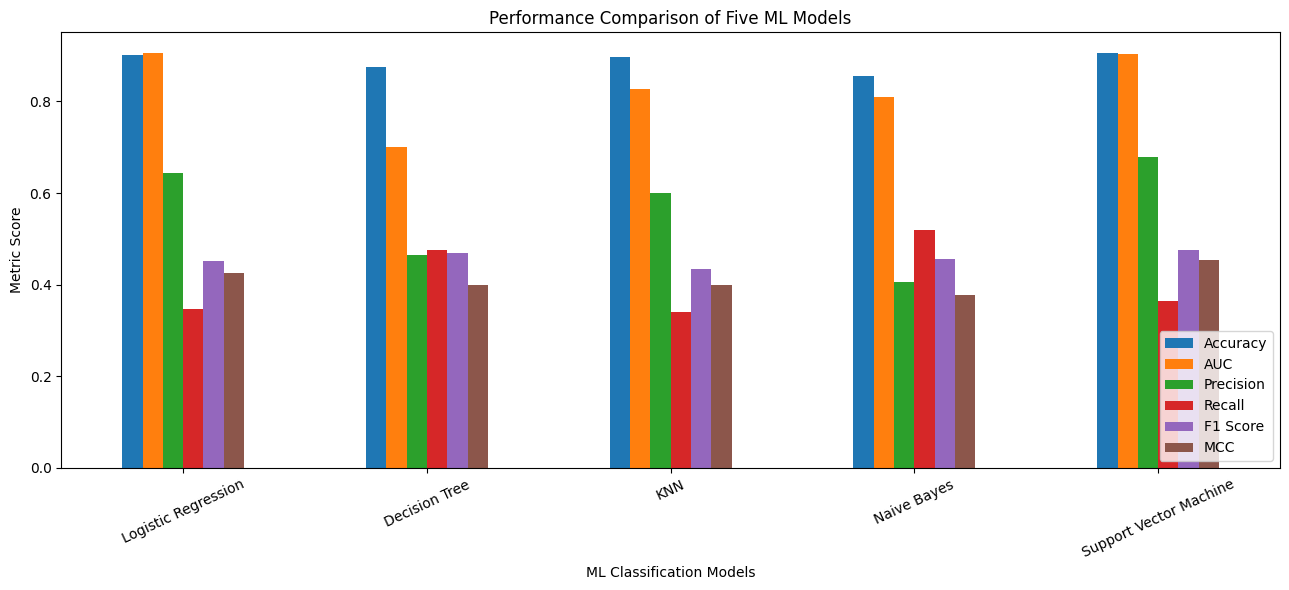

In [15]:
comparison_df.set_index("ML Model")[metrics].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Performance Comparison of Five ML Models")
plt.ylabel("Metric Score")
plt.xlabel("ML Classification Models")

plt.xticks(rotation=25)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [16]:
rank_df.to_csv(
    "model_ranking.csv",
    index=False
)

print("Model ranking saved successfully!")
print("Overall winner:", winner)

Model ranking saved successfully!
Overall winner: Support Vector Machine


In [17]:
test_data = X_test.copy()

test_data["y"] = y_test

test_data.to_csv(
    "test_data.csv",
    index=False
)

print("Test dataset created successfully!")
print("Test dataset shape:", test_data.shape)

Test dataset created successfully!
Test dataset shape: (9043, 17)


In [36]:
display(comparison_df)
display(rank_df)

,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC,Training Time (sec)
0,Logistic Regression,0.901250,0.905574,0.644483,0.347826,0.451811,0.426058,1.494571
1,Decision Tree,0.874599,0.701457,0.464880,0.475425,0.470093,0.399021,0.879483
2,KNN,0.896163,0.827721,0.599002,0.340265,0.433996,0.400128,0.191841
3,Naive Bayes,0.854805,0.810095,0.405904,0.519849,0.455864,0.377358,0.214473
4,Support Vector Machine,0.905562,0.903570,0.679577,0.364839,0.474785,0.453129,125.806000


,ML Model,Accuracy Rank,AUC Rank,Precision Rank,Recall Rank,F1 Score Rank,MCC Rank,Average Rank
4,Support Vector Machine,1.0,2.0,1.0,3.0,1.0,1.0,1.500000
0,Logistic Regression,2.0,1.0,2.0,4.0,4.0,2.0,2.500000
1,Decision Tree,4.0,5.0,4.0,2.0,2.0,4.0,3.500000
2,KNN,3.0,3.0,3.0,5.0,5.0,3.0,3.666667
3,Naive Bayes,5.0,4.0,5.0,1.0,3.0,5.0,3.833333
